# Generate Random Ints (5K)

### 1.0 Load Libraries 

In [7]:
# Load Libraries
from qiskit_ibm_runtime import QiskitRuntimeService

# for api token 
import keyring as k3

# for the quantum circuit
from qiskit.circuit import QuantumCircuit

# for the transpiler
from qiskit import transpile

# For the sampler
from qiskit_ibm_runtime import SamplerV2

print("Llibraries Loaded")

Llibraries Loaded


### 2.0 Set Backend 

In [2]:
# set the qubit count
n_qubits = 8

# Get the API token from keyring
api_token = k3.get_password('ibm_quantum', 'api_token')


# set up your backend 
service = QiskitRuntimeService(channel="ibm_quantum", token=api_token)
backend = service.least_busy(
    operational=True, 
    simulator=False, 
    min_num_qubits=n_qubits
)

print(f"Using backend: {backend}")
print("Backend Loaded")

Using backend: <IBMBackend('ibm_sherbrooke')>
Backend Loaded


### 3.1 Create and draw circuit 

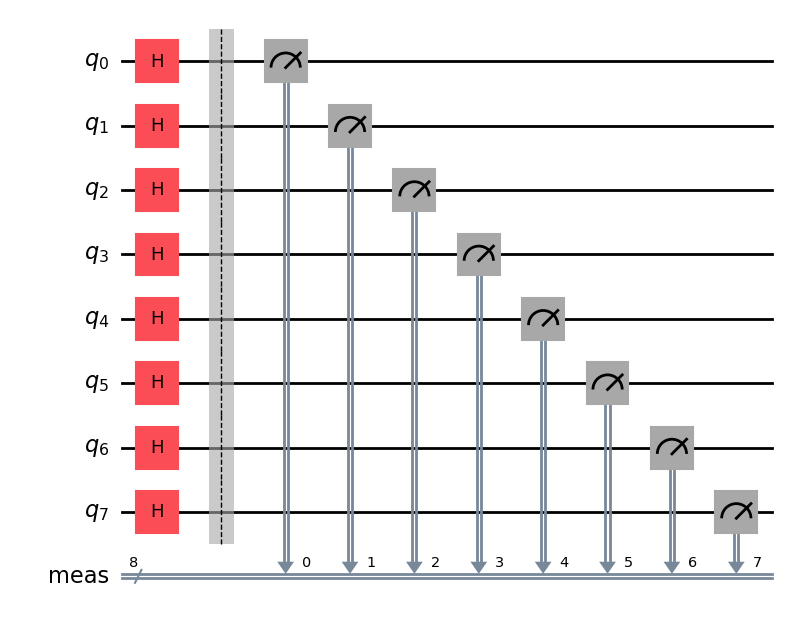

In [5]:
# Create a Quantum Circuit
n = 8
qc = QuantumCircuit(n)
for i in range(n):
    qc.h(i)
qc.measure_all()

qc.draw('mpl')


### 3.1 Transpile the Circuit 

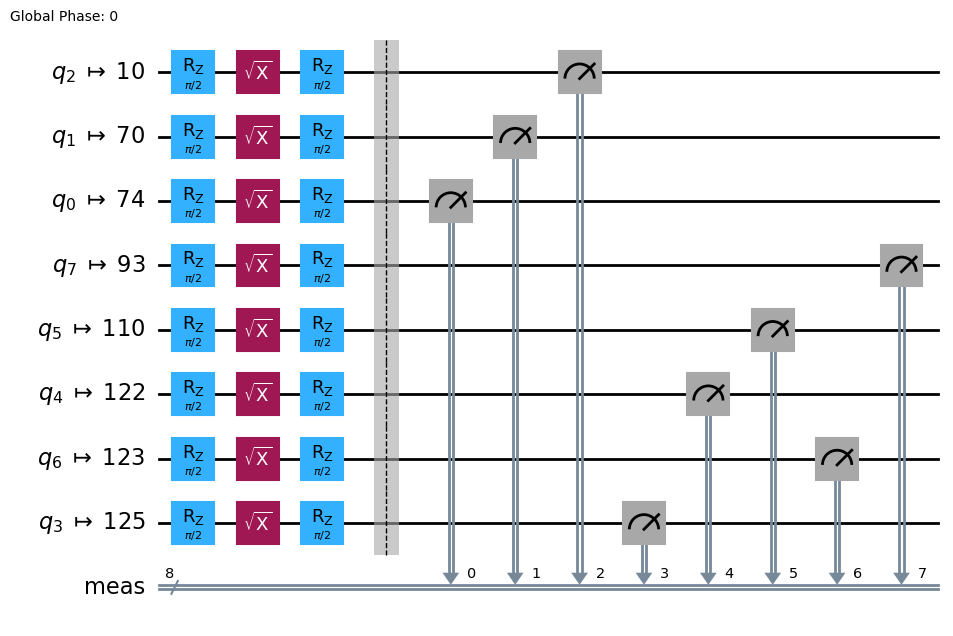

In [6]:
# Transpile the circuit
transpiled_circuit = transpile(qc, backend=backend)

# Draw the transpiled circuit
transpiled_circuit.draw('mpl')

### 4.0 Create PUB and Run 

In [8]:
# construct the PUB 
pub_qc_measurement = (transpiled_circuit) 

# Set the number of shots
n_shots = 5000

# Inaitialize the sampler
sampler = SamplerV2(backend)
job_qc_measurement = sampler.run([pub_qc_measurement], shots=n_shots)

# Extract results
result_qc_measurement = job_qc_measurement.result()
data_qc_measurement = result_qc_measurement[0].data
print("qc Measurement Results:")
print(data_qc_measurement)

qc Measurement Results:
DataBin(meas=BitArray(<shape=(), num_shots=5000, num_bits=8>))
